# Superstore Sales & Profitability Analysis
### Exploratory Data Analysis (EDA) • Data Cleaning • Customer & Product Insights

**Project objective:** understand sales, profit, shipping performance, customer value, and trends over time using the Superstore order-level dataset.

**Notebook workflow**
1. Load and inspect the dataset
2. Clean data types, duplicates, and date fields
3. Create analytical features
4. Explore sales, profit, products, customers, regions, and shipping
5. Review monthly trends and year-over-year sales growth

## 1. Imports and chart styling

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Consistent styling for all visualizations

sns.set_theme(style="darkgrid", context="paper", palette="deep")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 110,
})

## 2. Load the dataset

In [58]:
superstore_df = pd.read_csv('Downloads/superstore_eda_v1-1724655032.csv')

## 3. Initial data quality review

In [59]:
# Check top 10 rows

superstore_df.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit
0,1,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2016-138688,12/06/16,16/06/16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164
5,6,CA-2014-115812,09/06/14,2014-6-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7.0,0.00,14.1694
6,7,CA-2014-115812,09/06/14,2014-6-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4.0,0.00,1.9656
7,8,CA-2014-115812,09/06/14,2014-6-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6.0,0.20,90.7152
8,9,CA-2014-115812,09/06/14,2014-6-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,3.0,0.20,5.7825
9,10,CA-2014-115812,09/06/14,2014-6-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5.0,0.00,34.4700


In [60]:
# Check how many columns exist with what kind of data

In [61]:
superstore_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10014 entries, 0 to 10013
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10014 non-null  int64  
 1   Order ID       10014 non-null  object 
 2   Order Date     10014 non-null  object 
 3   Ship Date      10014 non-null  object 
 4   Ship Mode      9916 non-null   object 
 5   Customer ID    10014 non-null  object 
 6   Customer Name  10014 non-null  object 
 7   Segment        10014 non-null  object 
 8   Country        10014 non-null  object 
 9   City           10014 non-null  object 
 10  State          10014 non-null  object 
 11  Postal Code    10014 non-null  int64  
 12  Region         10014 non-null  object 
 13  Product ID     10014 non-null  object 
 14  Category       10014 non-null  object 
 15  Sub-Category   10014 non-null  object 
 16  Product Name   10014 non-null  object 
 17  Sales Price    10014 non-null  float64
 18  Quanti

In [62]:
# Check if multiple Country data exists

In [63]:
superstore_df['Country'].unique()

array(['United States'], dtype=object)

In [64]:
# Check how many Category are there

In [65]:
superstore_df['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [66]:
# Check unique values of each columns

In [67]:
for col in superstore_df.columns:
    print(f"\nColumn: {col}")
    print(f"Shape of unique values: {superstore_df[col].unique().shape}")
    print(superstore_df[col].unique())


Column: Row ID
Shape of unique values: (9994,)
[   1    2    3 ... 9992 9993 9994]

Column: Order ID
Shape of unique values: (5009,)
['CA-2016-152156' 'CA-2016-138688' 'US-2015-108966' ... 'CA-2014-110422'
 'CA-2017-121258' 'CA-2017-119914']

Column: Order Date
Shape of unique values: (1240,)
['08/11/16' '12/06/16' '11/10/15' ... '28/12/19' '12/04/15' '21/01/14']

Column: Ship Date
Shape of unique values: (1334,)
['11/11/16' '16/06/16' '18/10/15' ... '23/05/15' '2014-1-23' '03/03/17']

Column: Ship Mode
Shape of unique values: (5,)
['Second Class' 'Standard Class' 'First Class' nan 'Same Day']

Column: Customer ID
Shape of unique values: (793,)
['CG-12520' 'DV-13045' 'SO-20335' 'BH-11710' 'AA-10480' 'IM-15070'
 'HP-14815' 'PK-19075' 'AG-10270' 'ZD-21925' 'KB-16585' 'SF-20065'
 'EB-13870' 'EH-13945' 'TB-21520' 'MA-17560' 'GH-14485' 'SN-20710'
 'LC-16930' 'RA-19885' 'ES-14080' 'ON-18715' 'PO-18865' 'LH-16900'
 'DP-13000' 'JM-15265' 'TB-21055' 'KM-16720' 'PS-18970' 'BS-11590'
 'KD-16270'

In [68]:
# Check unique value for ship moe

superstore_df['Ship Mode'].unique()

array(['Second Class', 'Standard Class', 'First Class', nan, 'Same Day'],
      dtype=object)

## 4. Data Cleaning

In [69]:
#Identifying the duplicates

In [70]:
superstore_df[superstore_df.duplicated()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit
9994,9980,US-2016-103674,06/12/16,10/12/16,Standard Class,AP-10720,Anne Pryor,Home Office,United States,Los Angeles,...,90032,West,OFF-BI-10002026,Office Supplies,Binders,Ibico Recycled Linen-Style Covers,437.472,14.0,0.2,153.1152
9995,9981,US-2015-151435,06/09/15,09/09/15,Second Class,SW-20455,Shaun Weien,Consumer,United States,Lafayette,...,70506,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,85.980,1.0,0.0,22.3548
9996,18,CA-2014-167164,13/05/14,2014-5-15,Second Class,AG-10270,Alejandro Grove,Consumer,United States,West Jordan,...,84084,West,OFF-ST-10000107,Office Supplies,Storage,Fellowes Super Stor/Drawer,55.500,2.0,0.0,9.9900
9997,19,CA-2014-143336,27/08/14,2014-9-1,Second Class,ZD-21925,Zuschuss Donatelli,Consumer,United States,San Francisco,...,94109,West,OFF-AR-10003056,Office Supplies,Art,Newell 341,8.560,2.0,0.0,2.4824
9999,21,CA-2014-143336,27/08/14,2014-9-1,Second Class,ZD-21925,Zuschuss Donatelli,Consumer,United States,San Francisco,...,94109,West,OFF-BI-10002215,Office Supplies,Binders,"Wilson Jones Hanging View Binder, White, 1""",22.720,4.0,0.2,7.3840
10001,8853,CA-2014-119977,08/10/14,2014-10-13,Second Class,DN-13690,Duane Noonan,Consumer,United States,New York City,...,10011,East,OFF-PA-10003823,Office Supplies,Paper,Xerox 197,123.920,4.0,0.0,55.7640
10002,8854,US-2015-115343,22/09/15,25/09/15,First Class,FO-14305,Frank Olsen,Consumer,United States,Philadelphia,...,19143,East,OFF-SU-10000898,Office Supplies,Supplies,Acme Hot Forged Carbon Steel Scissors with Nic...,55.600,5.0,0.2,6.2550
10003,8855,US-2015-115343,22/09/15,25/09/15,First Class,FO-14305,Frank Olsen,Consumer,United States,Philadelphia,...,19143,East,TEC-AC-10003832,Technology,Accessories,Logitech�P710e Mobile Speakerphone,617.976,3.0,0.2,-7.7247
10004,1043,CA-2016-102981,06/09/16,09/09/16,Second Class,MO-17500,Mary O'Rourke,Consumer,United States,New York City,...,10035,East,FUR-BO-10001811,Furniture,Bookcases,"Atlantic Metals Mobile 5-Shelf Bookcases, Cust...",722.352,3.0,0.2,90.2940
10006,1045,CA-2017-115651,09/07/17,12/07/17,First Class,NS-18640,Noel Staavos,Corporate,United States,Chicago,...,60610,Central,OFF-AP-10000055,Office Supplies,Appliances,Belkin F9S820V06 8 Outlet Surge,58.464,9.0,0.8,-146.1600


In [71]:
#Shape before removing duplicates
print("Before:", superstore_df.shape[0])

#Number of duplicate rows
print("Duplicate rows:", superstore_df.duplicated().sum())

# Unique order ID before 
initial_unique_order_id = superstore_df['Order ID'].nunique()
print(f"Unique order IDs before {initial_unique_order_id}")

#Remove duplicates
df_deduplicated = superstore_df.drop_duplicates(keep="first").copy()

# Unique order ID after
duplicated_unique_order_id = df_deduplicated['Order ID'].nunique()
print(f"Unique order IDs after {initial_unique_order_id}")

# Shape after removing duplicates
print("After:", df_deduplicated.shape[0])



Before: 10014
Duplicate rows: 17
Unique order IDs before 5009
Unique order IDs after 5009
After: 9997


In [72]:
df_deduplicated.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales Price', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [73]:
#Changing to datetime


df_deduplicated['Order Date']

0        08/11/16
1        08/11/16
2        12/06/16
3        11/10/15
4        11/10/15
           ...   
9992     26/02/17
9993     04/05/17
9998     27/08/14
10000    02/07/15
10005    09/07/17
Name: Order Date, Length: 9997, dtype: object

In [74]:
df_deduplicated['Order Date'] = pd.to_datetime(df_deduplicated['Order Date'], format = '%d/%m/%y', errors='coerce')
df_deduplicated['Order Date']

0       2016-11-08
1       2016-11-08
2       2016-06-12
3       2015-10-11
4       2015-10-11
           ...    
9992    2017-02-26
9993    2017-05-04
9998    2014-08-27
10000   2015-07-02
10005   2017-07-09
Name: Order Date, Length: 9997, dtype: datetime64[ns]

In [75]:
df_deduplicated['Ship Date'] = pd.to_datetime(df_deduplicated['Ship Date'], format = '%d/%m/%y', errors='coerce')
df_deduplicated['Ship Date']

0       2016-11-11
1       2016-11-11
2       2016-06-16
3       2015-10-18
4       2015-10-18
           ...    
9992    2017-03-03
9993    2017-05-09
9998           NaT
10000   2015-07-04
10005   2017-07-12
Name: Ship Date, Length: 9997, dtype: datetime64[ns]

In [76]:
# Validate the changes and check the datatypes

df_deduplicated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9997 entries, 0 to 10005
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9997 non-null   int64         
 1   Order ID       9997 non-null   object        
 2   Order Date     9997 non-null   datetime64[ns]
 3   Ship Date      8056 non-null   datetime64[ns]
 4   Ship Mode      9899 non-null   object        
 5   Customer ID    9997 non-null   object        
 6   Customer Name  9997 non-null   object        
 7   Segment        9997 non-null   object        
 8   Country        9997 non-null   object        
 9   City           9997 non-null   object        
 10  State          9997 non-null   object        
 11  Postal Code    9997 non-null   int64         
 12  Region         9997 non-null   object        
 13  Product ID     9997 non-null   object        
 14  Category       9997 non-null   object        
 15  Sub-Category   9997 non-n

In [77]:
# Fill NaN value by order date with assumption order shipped on same date 

df_deduplicated['Ship Date'] = df_deduplicated['Ship Date'].fillna(df_deduplicated['Order Date'])
df_deduplicated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9997 entries, 0 to 10005
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9997 non-null   int64         
 1   Order ID       9997 non-null   object        
 2   Order Date     9997 non-null   datetime64[ns]
 3   Ship Date      9997 non-null   datetime64[ns]
 4   Ship Mode      9899 non-null   object        
 5   Customer ID    9997 non-null   object        
 6   Customer Name  9997 non-null   object        
 7   Segment        9997 non-null   object        
 8   Country        9997 non-null   object        
 9   City           9997 non-null   object        
 10  State          9997 non-null   object        
 11  Postal Code    9997 non-null   int64         
 12  Region         9997 non-null   object        
 13  Product ID     9997 non-null   object        
 14  Category       9997 non-null   object        
 15  Sub-Category   9997 non-n

In [78]:
# Correcting inconsistencies of order date using Order Year from Order ID

df_deduplicated['Order Year'] = df_deduplicated['Order ID'].apply(lambda x: int(x.split('-')[1]))
df_deduplicated['Order Date Year'] = df_deduplicated['Order Date'].dt.year
inconsistencies = df_deduplicated[df_deduplicated['Order Year']!= df_deduplicated['Order Date Year']]
inconsistencies

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year
62,63,CA-2015-135545,2017-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,TEC-AC-10004633,Technology,Accessories,Verbatim 25 GB 6x Blu-ray Single Layer Recorda...,13.980,2.0,0.0,6.1512,2015,2017
63,64,CA-2015-135545,2017-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,OFF-BI-10001078,Office Supplies,Binders,"Acco PRESSTEX Data Binder with Storage Hooks, ...",25.824,6.0,0.2,9.3612,2015,2017
64,65,CA-2015-135545,2017-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,OFF-PA-10003892,Office Supplies,Paper,Xerox 1943,146.730,3.0,0.0,68.9631,2015,2017
65,66,CA-2015-135545,2017-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,FUR-FU-10000397,Furniture,Furnishings,Luxo Economy Swing Arm Lamp,79.760,4.0,0.0,22.3328,2015,2017
943,944,CA-2015-120880,2013-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-PA-10004101,Office Supplies,Paper,Xerox 1894,32.400,5.0,0.0,15.5520,2015,2013
944,945,CA-2015-120880,2013-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-ST-10001496,Office Supplies,Storage,Standard Rollaway File with Lock,540.570,3.0,0.0,140.5482,2015,2013
945,946,CA-2015-120880,2013-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-BI-10002931,Office Supplies,Binders,"Avery Trapezoid Extra Heavy Duty 4"" Binders",167.760,5.0,0.2,62.9100,2015,2013
1152,1153,CA-2017-160395,2016-12-31,2017-01-06,Standard Class,KL-16555,Kelly Lampkin,Corporate,United States,Reno,...,OFF-AR-10003759,Office Supplies,Art,"Crayola Anti Dust Chalk, 12/Pack",3.640,2.0,0.0,1.6380,2017,2016
1153,1154,CA-2017-160395,2016-12-31,2017-01-06,Standard Class,KL-16555,Kelly Lampkin,Corporate,United States,Reno,...,OFF-BI-10003984,Office Supplies,Binders,Lock-Up Easel 'Spel-Binder',159.768,7.0,0.2,53.9217,2017,2016
2752,2753,CA-2015-155306,1999-04-17,2015-04-21,Standard Class,GA-14515,George Ashbrook,Consumer,United States,San Francisco,...,OFF-AR-10003251,Office Supplies,Art,Prang Drawing Pencil Set,5.560,2.0,0.0,2.2240,2015,1999


In [79]:
# Identifying inconsistencies index 

inconsistencies.index

Index([  62,   63,   64,   65,  943,  944,  945, 1152, 1153, 2752, 2753, 2754,
       2755, 2756, 2821, 3537, 3538, 3539, 3540, 4448, 4449, 4450, 4612, 4613,
       5289, 5290, 5291, 5372, 5373, 5374, 5738, 6341, 6387, 6388, 8586, 8587,
       8595, 8596, 9942, 9943],
      dtype='int64')

In [80]:
# Identifying inconsistencies shape

inconsistencies.shape

(40, 23)

In [81]:
# Correcting inconsistencies in order date

def correct_year(row):
    return row['Order Date'].replace(year = row['Order Year'])

df_deduplicated.loc[inconsistencies.index, ['Order Date']] = (df_deduplicated.loc[inconsistencies.index].apply(correct_year, axis =1))
df_deduplicated.loc[inconsistencies.index]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year
62,63,CA-2015-135545,2015-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,TEC-AC-10004633,Technology,Accessories,Verbatim 25 GB 6x Blu-ray Single Layer Recorda...,13.980,2.0,0.0,6.1512,2015,2017
63,64,CA-2015-135545,2015-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,OFF-BI-10001078,Office Supplies,Binders,"Acco PRESSTEX Data Binder with Storage Hooks, ...",25.824,6.0,0.2,9.3612,2015,2017
64,65,CA-2015-135545,2015-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,OFF-PA-10003892,Office Supplies,Paper,Xerox 1943,146.730,3.0,0.0,68.9631,2015,2017
65,66,CA-2015-135545,2015-11-24,2015-11-30,Standard Class,KM-16720,Kunst Miller,Consumer,United States,Los Angeles,...,FUR-FU-10000397,Furniture,Furnishings,Luxo Economy Swing Arm Lamp,79.760,4.0,0.0,22.3328,2015,2017
943,944,CA-2015-120880,2015-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-PA-10004101,Office Supplies,Paper,Xerox 1894,32.400,5.0,0.0,15.5520,2015,2013
944,945,CA-2015-120880,2015-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-ST-10001496,Office Supplies,Storage,Standard Rollaway File with Lock,540.570,3.0,0.0,140.5482,2015,2013
945,946,CA-2015-120880,2015-05-29,2015-06-03,Standard Class,JL-15850,John Lucas,Consumer,United States,Seattle,...,OFF-BI-10002931,Office Supplies,Binders,"Avery Trapezoid Extra Heavy Duty 4"" Binders",167.760,5.0,0.2,62.9100,2015,2013
1152,1153,CA-2017-160395,2017-12-31,2017-01-06,Standard Class,KL-16555,Kelly Lampkin,Corporate,United States,Reno,...,OFF-AR-10003759,Office Supplies,Art,"Crayola Anti Dust Chalk, 12/Pack",3.640,2.0,0.0,1.6380,2017,2016
1153,1154,CA-2017-160395,2017-12-31,2017-01-06,Standard Class,KL-16555,Kelly Lampkin,Corporate,United States,Reno,...,OFF-BI-10003984,Office Supplies,Binders,Lock-Up Easel 'Spel-Binder',159.768,7.0,0.2,53.9217,2017,2016
2752,2753,CA-2015-155306,2015-04-17,2015-04-21,Standard Class,GA-14515,George Ashbrook,Consumer,United States,San Francisco,...,OFF-AR-10003251,Office Supplies,Art,Prang Drawing Pencil Set,5.560,2.0,0.0,2.2240,2015,1999


In [82]:
# Print impacted rows and order IDs

impacted_rows = inconsistencies.shape[0]
impacted_order_ids = inconsistencies['Order ID'].nunique()
print(f"Rows impacted by date correction: {impacted_rows}")
print(f"Distinct Order IDs impacted: {impacted_order_ids}")

Rows impacted by date correction: 40
Distinct Order IDs impacted: 16


In [83]:
# Calculating Days to Ship

df_deduplicated['Days to Ship'] = (df_deduplicated['Ship Date'] - df_deduplicated['Order Date']).dt.days
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year,Days to Ship
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2016,2016,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2016,2016,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2016,2016,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2015,2015,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2015,2015,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200,2017,2017,5
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.1600,2.0,0.00,72.9480,2017,2017,5
9998,20,CA-2014-143336,2014-08-27,2014-08-27,Second Class,ZD-21925,Zuschuss Donatelli,Consumer,United States,San Francisco,...,Technology,Phones,Cisco SPA 501G IP Phone,213.4800,3.0,0.20,16.0110,2014,2014,0
10000,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Frank Atkinson,Corporate,United States,Raleigh,...,Office Supplies,Paper,Things To Do Today Pad,-9.3920,2.0,0.20,3.2872,2015,2015,2


In [84]:
df_deduplicated['Ship Mode'].value_counts()

Ship Mode
Standard Class    5903
Second Class      1946
First Class       1540
Same Day           510
Name: count, dtype: int64

In [85]:
df_deduplicated['Days to Ship'].unique()

array([   3,    4,    7,    0,    5,    2,    6,    1, -359, -360,  365,
        731, -363, 1096, 5479])

In [86]:
df_deduplicated['Days to Ship'].value_counts()

Days to Ship
 0       2361
 4       2202
 5       1692
 2       1049
 6        996
 3        837
 7        517
 1        325
-359        5
 365        4
 731        3
 1096       2
 5479       2
-360        1
-363        1
Name: count, dtype: int64

In [87]:
df_deduplicated['Ship Mode'].value_counts()

Ship Mode
Standard Class    5903
Second Class      1946
First Class       1540
Same Day           510
Name: count, dtype: int64

In [88]:
#Setting Days to Ship 0 as "Same Day" if 7, "Standard Class" if Days to Ship is 7
df_deduplicated['Ship Mode'] = df_deduplicated.apply(lambda row: 'Same Day' if row['Days to Ship'] == 0 else ('Standard Class' if row['Days to Ship'] ==7 else row['Ship Mode']), axis=1)
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year,Days to Ship
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2016,2016,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2016,2016,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2016,2016,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2015,2015,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2015,2015,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200,2017,2017,5
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.1600,2.0,0.00,72.9480,2017,2017,5
9998,20,CA-2014-143336,2014-08-27,2014-08-27,Same Day,ZD-21925,Zuschuss Donatelli,Consumer,United States,San Francisco,...,Technology,Phones,Cisco SPA 501G IP Phone,213.4800,3.0,0.20,16.0110,2014,2014,0
10000,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Frank Atkinson,Corporate,United States,Raleigh,...,Office Supplies,Paper,Things To Do Today Pad,-9.3920,2.0,0.20,3.2872,2015,2015,2


In [89]:
df_deduplicated['Ship Mode'].value_counts()

Ship Mode
Standard Class    4778
Same Day          2387
Second Class      1576
First Class       1256
Name: count, dtype: int64

In [90]:
# Filling Quantity with nearest value

mean_quantity = df_deduplicated['Quantity'].mean()
mean_quantity

np.float64(3.790860807696162)

In [91]:
median_quantity = df_deduplicated['Quantity'].median()
median_quantity

3.0

In [92]:
# Imputing median since mean give decimal value

df_deduplicated['Quantity'] = df_deduplicated['Quantity'].fillna(median_quantity)
df_deduplicated['Quantity']

0        2.0
1        3.0
2        2.0
3        5.0
4        2.0
        ... 
9992     4.0
9993     2.0
9998     3.0
10000    2.0
10005    5.0
Name: Quantity, Length: 9997, dtype: float64

In [93]:
df_deduplicated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9997 entries, 0 to 10005
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Row ID           9997 non-null   int64         
 1   Order ID         9997 non-null   object        
 2   Order Date       9997 non-null   datetime64[ns]
 3   Ship Date        9997 non-null   datetime64[ns]
 4   Ship Mode        9997 non-null   object        
 5   Customer ID      9997 non-null   object        
 6   Customer Name    9997 non-null   object        
 7   Segment          9997 non-null   object        
 8   Country          9997 non-null   object        
 9   City             9997 non-null   object        
 10  State            9997 non-null   object        
 11  Postal Code      9997 non-null   int64         
 12  Region           9997 non-null   object        
 13  Product ID       9997 non-null   object        
 14  Category         9997 non-null   object     

In [94]:
df_deduplicated['Quantity'].unique()

array([ 2.,  3.,  5.,  7.,  4.,  6.,  9.,  1.,  8., 14., 11., 13., 10.,
       12.])

In [95]:
df_deduplicated[['Customer Name', 'Customer ID']].head(5)

,Customer Name,Customer ID
0,Claire Gute,CG-12520
1,Claire Gute,CG-12520
2,Darrin Van Huff,DV-13045
3,Sean O'Donnell,SO-20335
4,Sean O'Donnell,SO-20335


In [96]:
# Data shows Customer name Initials are 1st 2 letters of Customer ID, hence creating another column with that
df_deduplicated.drop(columns = ['Customer Name'], inplace = True)


In [97]:
df_deduplicated['Customer Name Masked'] = df_deduplicated['Customer ID'].apply(lambda x: x.split('-')[0])
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Sub-Category,Product Name,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year,Days to Ship,Customer Name Masked
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2016,2016,3,CG
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2016,2016,3,CG
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2016,2016,4,DV
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2015,2015,7,SO
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2015,2015,7,SO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,United States,Costa Mesa,California,...,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200,2017,2017,5,DB
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Consumer,United States,Westminster,California,...,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.1600,2.0,0.00,72.9480,2017,2017,5,CC
9998,20,CA-2014-143336,2014-08-27,2014-08-27,Same Day,ZD-21925,Consumer,United States,San Francisco,California,...,Phones,Cisco SPA 501G IP Phone,213.4800,3.0,0.20,16.0110,2014,2014,0,ZD
10000,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Corporate,United States,Raleigh,North Carolina,...,Paper,Things To Do Today Pad,-9.3920,2.0,0.20,3.2872,2015,2015,2,FA


In [98]:
# Checking inconsistencies in Postal Code and making in 5 digit string values

df_deduplicated['Postal Code'].unique()

array([42420, 90036, 33311, 90032, 28027, 98103, 76106, 53711, 84084,
       94109, 68025, 19140, 84057, 90049, 77095, 75080, 77041, 60540,
       32935, 55122, 48185, 19901, 47150, 10024, 12180, 90004, 60610,
       85234, 22153, 10009, 49201, 38109, 77070, 35601, 94122, 27707,
       60623, 29203, 55901, 55407, 97206, 55106, 80013, 28205, 60462,
       10035, 50322, 43229, 37620, 19805, 61701, 85023, 95661, 64055,
       91104, 43055, 53132, 85254, 95123, 98105, 98115, 73034, 90045,
       19134, 88220, 78207, 77036, 62521, 71203,  6824, 75051, 92374,
       45011,  7090, 19120, 44312, 80219, 75220, 37064, 90604, 48601,
       44256, 43017, 48227, 38401, 33614, 95051, 55044, 92037, 77506,
       94513, 27514,  7960, 45231, 94110, 90301, 33319, 80906,  7109,
       48180,  8701, 22204, 80004,  7601, 33710, 19143, 90805, 92345,
       37130, 84041, 78745,  1852, 31907,  6040, 78550, 85705, 62301,
        2038, 33024, 98198, 61604, 89115,  2886, 33180, 28403, 92646,
       40475, 80027,

In [99]:
df_deduplicated['Postal Code'] = df_deduplicated['Postal Code'].astype(str).str.zfill(5)
df_deduplicated['Postal Code'].unique()

array(['42420', '90036', '33311', '90032', '28027', '98103', '76106',
       '53711', '84084', '94109', '68025', '19140', '84057', '90049',
       '77095', '75080', '77041', '60540', '32935', '55122', '48185',
       '19901', '47150', '10024', '12180', '90004', '60610', '85234',
       '22153', '10009', '49201', '38109', '77070', '35601', '94122',
       '27707', '60623', '29203', '55901', '55407', '97206', '55106',
       '80013', '28205', '60462', '10035', '50322', '43229', '37620',
       '19805', '61701', '85023', '95661', '64055', '91104', '43055',
       '53132', '85254', '95123', '98105', '98115', '73034', '90045',
       '19134', '88220', '78207', '77036', '62521', '71203', '06824',
       '75051', '92374', '45011', '07090', '19120', '44312', '80219',
       '75220', '37064', '90604', '48601', '44256', '43017', '48227',
       '38401', '33614', '95051', '55044', '92037', '77506', '94513',
       '27514', '07960', '45231', '94110', '90301', '33319', '80906',
       '07109', '481

In [100]:
df_deduplicated[['Quantity', 'Sales Price']].head(10)

,Quantity,Sales Price
0,2.0,261.9600
1,3.0,731.9400
2,2.0,14.6200
3,5.0,957.5775
4,2.0,22.3680
5,7.0,48.8600
6,4.0,7.2800
7,6.0,907.1520
8,3.0,18.5040
9,5.0,114.9000


In [101]:
# Converting Quantity and Sales price from Object to float
df_deduplicated[['Quantity','Sales Price']].dtypes

Quantity       float64
Sales Price    float64
dtype: object

In [102]:
df_deduplicated['Quantity'] = pd.to_numeric(df_deduplicated['Quantity'], errors = 'coerce')
df_deduplicated['Sales Price'] = pd.to_numeric(df_deduplicated['Sales Price'], errors = 'coerce')
df_deduplicated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9997 entries, 0 to 10005
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Row ID                9997 non-null   int64         
 1   Order ID              9997 non-null   object        
 2   Order Date            9997 non-null   datetime64[ns]
 3   Ship Date             9997 non-null   datetime64[ns]
 4   Ship Mode             9997 non-null   object        
 5   Customer ID           9997 non-null   object        
 6   Segment               9997 non-null   object        
 7   Country               9997 non-null   object        
 8   City                  9997 non-null   object        
 9   State                 9997 non-null   object        
 10  Postal Code           9997 non-null   object        
 11  Region                9997 non-null   object        
 12  Product ID            9997 non-null   object        
 13  Category              

In [103]:
#Coverting Quantity to Integer value
df_deduplicated['Quantity'] = df_deduplicated['Quantity'].astype(dtype = 'Int64')

In [104]:
df_deduplicated['State'].value_counts()

State
California              1906
New York                1105
Texas                    918
Pennsylvania             587
Illinois                 493
Ohio                     469
Washington               457
Florida                  383
Michigan                 255
North Carolina           250
Arizona                  224
Virginia                 224
Georgia                  184
Tennessee                183
Colorado                 182
Indiana                  149
Kentucky                 139
Massachusetts            135
Oregon                   124
Wisconsin                110
Maryland                 105
New Jersey                99
Delaware                  96
CA                        96
Minnesota                 89
Connecticut               82
TX                        67
Oklahoma                  66
Missouri                  66
Alabama                   61
Arkansas                  60
Rhode Island              56
Utah                      53
Mississippi               53
WA\     

In [105]:
len(df_deduplicated['State'].value_counts())

54

In [106]:
# Standardize known state abbreviations only when the exact source values occur.

state_mapping = {'CA' : 'California' , 'TX' : 'Texas' , 'WA\\' : 'Washington', 'NY' : 'New York', 'NJ' : 'New Jersey'}
df_deduplicated['State'] = df_deduplicated['State'].replace(state_mapping)

In [107]:
df_deduplicated['State'].value_counts()

State
California              1906
New York                1128
Texas                    985
Pennsylvania             587
Washington               506
Illinois                 493
Ohio                     469
Florida                  383
Michigan                 255
North Carolina           250
Arizona                  224
Virginia                 224
Georgia                  184
Tennessee                183
Colorado                 182
Indiana                  149
Kentucky                 139
Massachusetts            135
New Jersey               130
Oregon                   124
Wisconsin                110
Maryland                 105
CA                        96
Delaware                  96
Minnesota                 89
Connecticut               82
Missouri                  66
Oklahoma                  66
Alabama                   61
Arkansas                  60
Rhode Island              56
Utah                      53
Mississippi               53
Louisiana                 42
South Ca

In [108]:
df_deduplicated['Original Price'] = df_deduplicated['Sales Price']/(1-df_deduplicated['Discount'])
df_deduplicated['Discount Price'] = df_deduplicated['Discount'] * df_deduplicated['Original Price']
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Sales Price,Quantity,Discount,Profit,Order Year,Order Date Year,Days to Ship,Customer Name Masked,Original Price,Discount Price
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,261.9600,2,0.00,41.9136,2016,2016,3,CG,261.96,0.0000
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,731.9400,3,0.00,219.5820,2016,2016,3,CG,731.94,0.0000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,...,14.6200,2,0.00,6.8714,2016,2016,4,DV,14.62,0.0000
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,957.5775,5,0.45,-383.0310,2015,2015,7,SO,1741.05,783.4725
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,22.3680,2,0.20,2.5164,2015,2015,7,SO,27.96,5.5920
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,United States,Costa Mesa,California,...,29.6000,4,0.00,13.3200,2017,2017,5,DB,29.60,0.0000
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Consumer,United States,Westminster,California,...,243.1600,2,0.00,72.9480,2017,2017,5,CC,243.16,0.0000
9998,20,CA-2014-143336,2014-08-27,2014-08-27,Same Day,ZD-21925,Consumer,United States,San Francisco,California,...,213.4800,3,0.20,16.0110,2014,2014,0,ZD,266.85,53.3700
10000,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Corporate,United States,Raleigh,North Carolina,...,-9.3920,2,0.20,3.2872,2015,2015,2,FA,-11.74,-2.3480


## 4. Feature Engineering

In [109]:
df_deduplicated['Total Sales'] = df_deduplicated['Sales Price']*df_deduplicated['Quantity']
df_deduplicated['Total Profit'] = df_deduplicated['Profit']*df_deduplicated['Quantity']
df_deduplicated['Total Discount'] = df_deduplicated['Discount']*df_deduplicated['Quantity']

In [110]:
df_deduplicated['Shipping Urgency'] = df_deduplicated['Days to Ship'].apply(lambda x: 'Immediate' if x==0 else ('Urgent' if 1 <= x <=3 else 'Standard'))
df_deduplicated['Shipping Urgency'].value_counts()

Shipping Urgency
Standard     5425
Immediate    2361
Urgent       2211
Name: count, dtype: int64

In [111]:
df_deduplicated['Days Since Last Order'] = df_deduplicated.sort_values(['Customer ID', 'Order Date']).groupby('Customer ID')['Order Date'].diff().dt.days.astype('Int64')

In [112]:
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Order Date Year,Days to Ship,Customer Name Masked,Original Price,Discount Price,Total Sales,Total Profit,Total Discount,Shipping Urgency,Days Since Last Order
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,2016,3,CG,261.96,0.0000,523.92,83.8272,0.0,Urgent,390
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,2016,3,CG,731.94,0.0000,2195.82,658.746,0.0,Urgent,0
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,...,2016,4,DV,14.62,0.0000,29.24,13.7428,0.0,Standard,<NA>
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,2015,7,SO,1741.05,783.4725,4787.8875,-1915.155,2.25,Standard,<NA>
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,2015,7,SO,27.96,5.5920,44.736,5.0328,0.4,Standard,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,United States,Costa Mesa,California,...,2017,5,DB,29.60,0.0000,118.4,53.28,0.0,Standard,0
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Consumer,United States,Westminster,California,...,2017,5,CC,243.16,0.0000,486.32,145.896,0.0,Standard,215
9998,20,CA-2014-143336,2014-08-27,2014-08-27,Same Day,ZD-21925,Consumer,United States,San Francisco,California,...,2014,0,ZD,266.85,53.3700,640.44,48.033,0.6,Immediate,0
10000,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Corporate,United States,Raleigh,North Carolina,...,2015,2,FA,-11.74,-2.3480,-18.784,6.5744,0.4,Urgent,0


In [113]:
total_per_customer = (
    df_deduplicated.groupby('Customer ID')[['Total Sales', 'Total Discount', 'Quantity']]
    .sum()
    .reset_index()
)

In [114]:
total_per_customer.columns = ['Customer ID', 'Total Sales Per Customer' , 'Total Discount Per Customer' , 'Total Quantity Per Customer']

In [115]:
df_deduplicated = pd.merge(df_deduplicated, total_per_customer, on = 'Customer ID' , how = 'left')

In [116]:
df_deduplicated

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Original Price,Discount Price,Total Sales,Total Profit,Total Discount,Shipping Urgency,Days Since Last Order,Total Sales Per Customer,Total Discount Per Customer,Total Quantity Per Customer
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,261.96,0.0000,523.92,83.8272,0.0,Urgent,390,3549.66,4.2,14
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,...,731.94,0.0000,2195.82,658.746,0.0,Urgent,0,3549.66,4.2,14
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,...,14.62,0.0000,29.24,13.7428,0.0,Standard,<NA>,6156.894,6.4,28
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,1741.05,783.4725,4787.8875,-1915.155,2.25,Standard,<NA>,10343.1775,6.75,52
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,...,27.96,5.5920,44.736,5.0328,0.4,Standard,0,10343.1775,6.75,52
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Consumer,United States,Costa Mesa,California,...,29.60,0.0000,118.4,53.28,0.0,Standard,0,20617.746,9.2,48
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Consumer,United States,Westminster,California,...,243.16,0.0000,486.32,145.896,0.0,Standard,215,20295.602,12.0,81
9994,20,CA-2014-143336,2014-08-27,2014-08-27,Same Day,ZD-21925,Consumer,United States,San Francisco,California,...,266.85,53.3700,640.44,48.033,0.6,Immediate,0,7132.888,4.4,35
9995,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Corporate,United States,Raleigh,North Carolina,...,-11.74,-2.3480,-18.784,6.5744,0.4,Urgent,0,9489.756,13.2,60


In [117]:
# Check how many unique Customer ID total_per_customer Dataframe has
total_per_customer

,Customer ID,Total Sales Per Customer,Total Discount Per Customer,Total Quantity Per Customer
0,AA-10315,16073.344,3.2,30
1,AA-10375,2734.83,3.8,41
2,AA-10480,5493.936,0.6,36
3,AA-10645,22927.855,4.35,64
4,AB-10015,1984.48,0.6,13
...,...,...,...,...
788,XP-21865,8676.214,6.2,100
789,YC-21895,27208.926,1.8,31
790,YS-21880,46478.992,3.6,58
791,ZC-21910,40212.889,23.4,105


## 6. Executive Overview

In [118]:
#Match is with unique Customer ID from df_deduplicated
df_deduplicated['Customer ID'].nunique()

793

In [119]:
# Identifying Missing Values
df_deduplicated['Total Sales Per Customer'].isna().sum()

np.int64(0)

In [120]:
# Identifying Missing Values
df_deduplicated['Total Discount Per Customer'].isna().sum()

np.int64(0)

In [121]:
# Identifying Missing Values
df_deduplicated['Total Quantity Per Customer'].isna().sum()

np.int64(0)

In [122]:
negative_sales = df_deduplicated[df_deduplicated['Sales Price'] < 0]
negative_sales

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Original Price,Discount Price,Total Sales,Total Profit,Total Discount,Shipping Urgency,Days Since Last Order,Total Sales Per Customer,Total Discount Per Customer,Total Quantity Per Customer
9794,9795,CA-2014-127166,2014-05-21,2014-05-21,Same Day,KH-16360,Consumer,United States,Houston,Texas,...,-91.20,-72.960,-54.72,-93.024,2.4,Immediate,0,13556.588,6.4,40
9984,9985,CA-2015-100251,2015-05-17,2015-05-23,Standard Class,DV-13465,Consumer,United States,Long Beach,New York,...,-31.50,-0.000,-315.0,151.2,0.0,Standard,329,12033.733,7.7,62
9995,8852,CA-2015-140718,2015-07-02,2015-07-04,First Class,FA-14230,Corporate,United States,Raleigh,North Carolina,...,-11.74,-2.348,-18.784,6.5744,0.4,Urgent,0,9489.756,13.2,60
9996,1044,CA-2017-115651,2017-07-09,2017-07-12,First Class,NS-18640,Corporate,United States,Chicago,Illinois,...,-11.05,-2.210,-44.2,14.9175,1.0,Urgent,0,12772.477,27.0,118


In [123]:
# Creating function to remove outliers

def remove_outliers(df, columns):
    Q1 = df[columns].quantile(0.25)
    Q3 = df[columns].quantile(0.75)
    IQR = Q3-Q1
    lower_bound = Q1-3*IQR
    upper_bound = Q3+3*IQR

    print(f"detecting outliers of in'{columns}' using 3*IQR...")
    outliers = df[(df[columns] < lower_bound) | (df[columns] > upper_bound)]
    print(f"Outliers found {outliers.shape[0]} rows")

    df_cleaned = df[~((df[columns] < lower_bound) | (df[columns] > upper_bound))]

    impacted_rows = outliers.shape[0]
    impacted_order_ids = outliers['Order ID'].nunique()
    print(f"Distinct impacted Order IDs: {impacted_order_ids}")

    return lower_bound, upper_bound, df_cleaned

In [124]:
lower_bound , upper_bound , df_cleaned = remove_outliers(df_deduplicated, 'Sales Price')
lower_bound , upper_bound 

detecting outliers of in'Sales Price' using 3*IQR...
Outliers found 668 rows
Distinct impacted Order IDs: 617


(np.float64(-560.8599999999999), np.float64(788.04))

In [125]:
lower_bound , upper_bound , df_cleaned = remove_outliers(df_cleaned, 'Profit')
lower_bound , upper_bound 

detecting outliers of in'Profit' using 3*IQR...
Outliers found 882 rows
Distinct impacted Order IDs: 803


(np.float64(-64.46879999999999), np.float64(89.856))

In [126]:
df_cleaned.shape

(8447, 34)

In [127]:
df_deduplicated.shape

(9997, 34)

In [128]:
df_deduplicated = df_deduplicated.copy() #Deep Copy

sales_sum = df_deduplicated.groupby('Customer ID')['Total Sales'].transform('sum')
profit_sum = df_deduplicated.groupby('Customer ID')['Total Profit'].transform('sum')

#use rank to avoid many identical-bin edges; drop duplicates if needed

df_deduplicated.loc[:,'Customer Sales Quintile'] = (pd.qcut(sales_sum.rank(method = 'first'), 5, labels = False, duplicates = 'drop') +1)
df_deduplicated.loc[:,'Customer Profit Quintile'] = (pd.qcut(profit_sum.rank(method = 'first'), 5 , labels = False, duplicates = 'drop') +1)

# create crosss grid to check the view

cross_grid = pd.crosstab(df_deduplicated['Customer Sales Quintile'], df_deduplicated['Customer Profit Quintile'])
print(cross_grid)
                                                    

Customer Profit Quintile    1     2    3    4     5
Customer Sales Quintile                            
1                         493  1121  386    0     0
2                         465   427  815  292     0
3                         348   191  568  798    94
4                         334   166  193  691   615
5                         360    94   37  218  1291


## 7. Product Performane

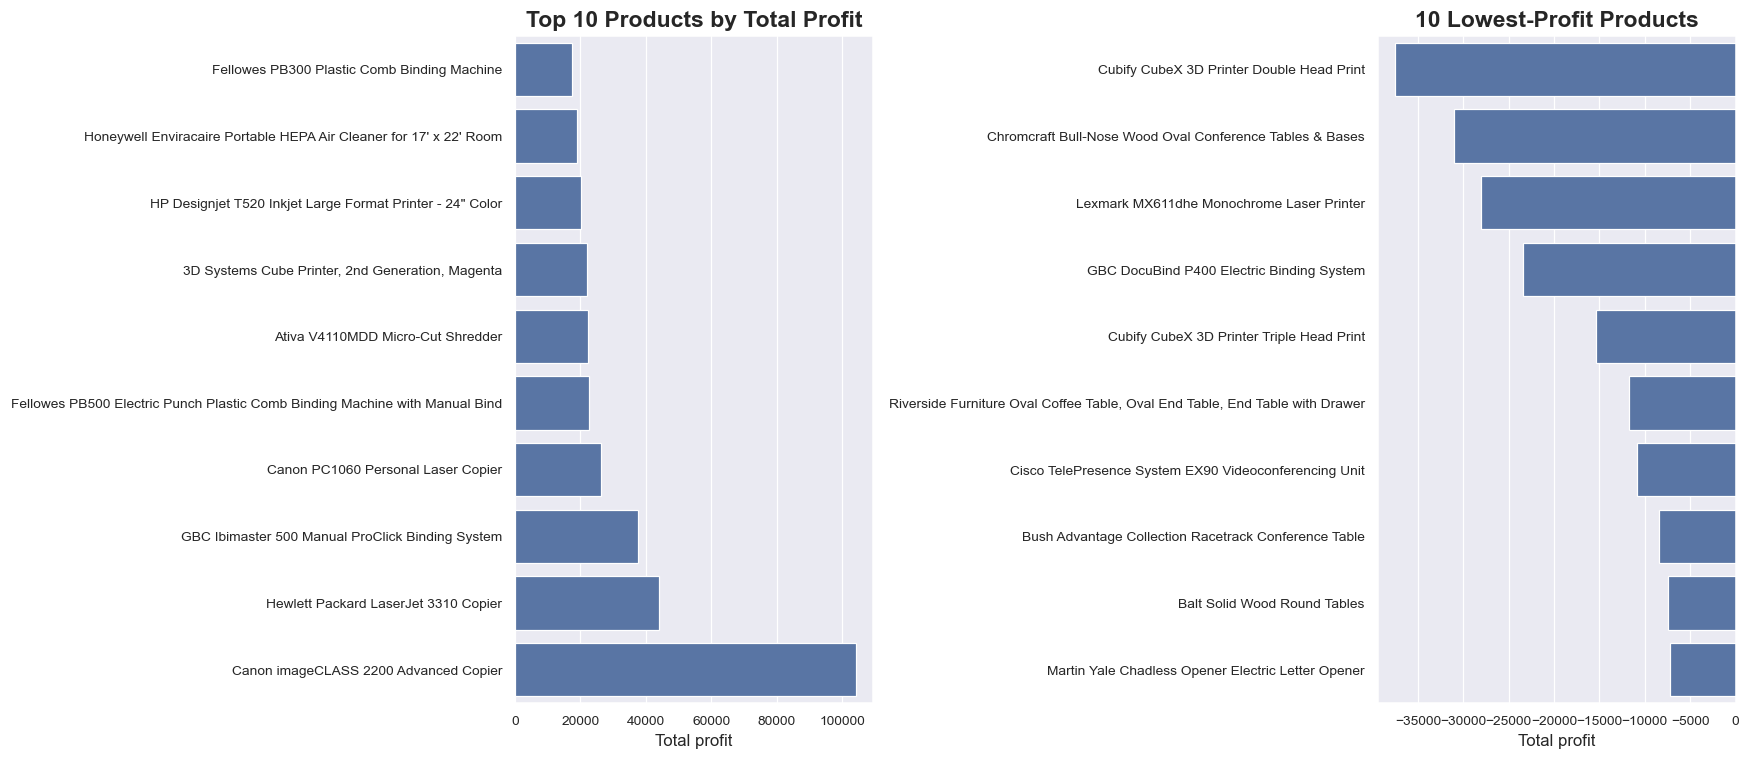

,Product Name,Total Profit
404,Canon imageCLASS 2200 Advanced Copier,104159.7024
805,Hewlett Packard LaserJet 3310 Copier,44087.2652
688,GBC Ibimaster 500 Manual ProClick Binding System,37592.412
400,Canon PC1060 Personal Laser Copier,26326.6239
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,22496.523
165,Ativa V4110MDD Micro-Cut Shredder,22294.6815
19,"3D Systems Cube Printer, 2nd Generation, Magenta",21969.831
787,HP Designjet T520 Inkjet Large Format Printer ...,20124.885
859,Honeywell Enviracaire Portable HEPA Air Cleane...,19001.08
649,Fellowes PB300 Plastic Comb Binding Machine,17440.1505


,Product Name,Total Profit
1043,Martin Yale Chadless Opener Electric Letter Op...,-7195.4784
285,Balt Solid Wood Round Tables,-7389.4095
376,Bush Advantage Collection Racetrack Conference...,-8450.2632
444,Cisco TelePresence System EX90 Videoconferenci...,-10866.4704
1349,"Riverside Furniture Oval Coffee Table, Oval En...",-11783.798
476,Cubify CubeX 3D Printer Triple Head Print,-15359.9616
683,GBC DocuBind P400 Electric Binding System,-23381.8082
985,Lexmark MX611dhe Monochrome Laser Printer,-28049.835
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-30976.0956
475,Cubify CubeX 3D Printer Double Head Print,-37559.8748


In [135]:
if {"Product Name", "Total Profit"}.issubset(df_deduplicated.columns):
    product_profit = (
        df_deduplicated.groupby("Product Name", as_index=False)["Total Profit"]
          .sum()
          .sort_values("Total Profit", ascending=False)
    )
    top_profitable = product_profit.head(10).sort_values("Total Profit")
    bottom_profit = product_profit.head(0)  # replaced below with lowest-profit products
    bottom_profit = product_profit.tail(10).sort_values("Total Profit")

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    sns.barplot(data=top_profitable, x="Total Profit", y="Product Name", ax=axes[0])
    axes[0].set_title("Top 10 Products by Total Profit")
    axes[0].set_xlabel("Total profit")
    axes[0].set_ylabel("")

    sns.barplot(data=bottom_profit, x="Total Profit", y="Product Name", ax=axes[1])
    axes[1].set_title("10 Lowest-Profit Products")
    axes[1].set_xlabel("Total profit")
    axes[1].set_ylabel("")
    plt.tight_layout()
    plt.show()

    display(product_profit.head(10))
    display(product_profit.tail(10))

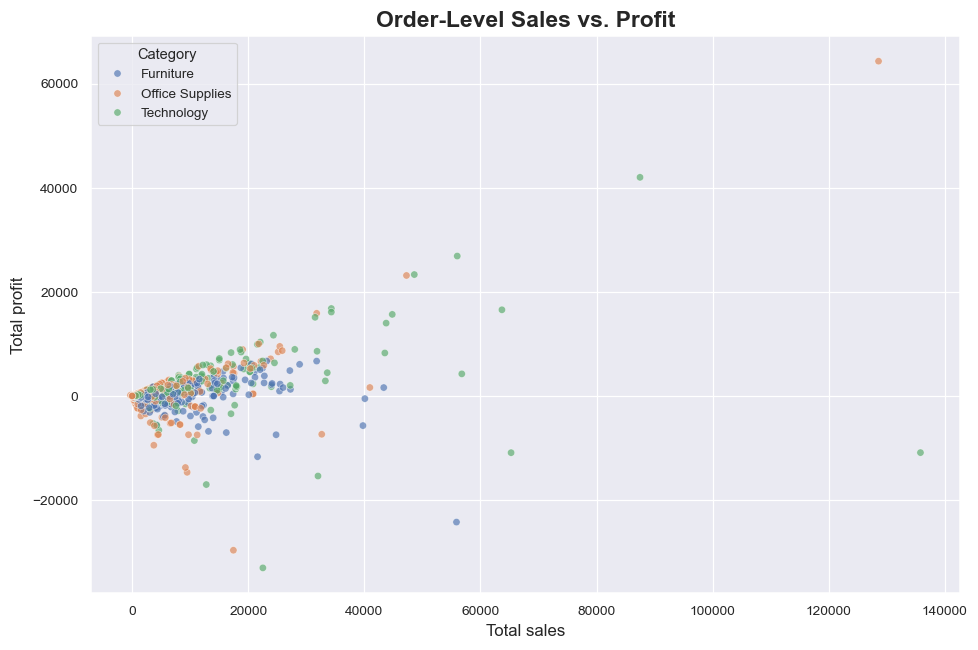

In [133]:
# Sales and profit relationship: inspect the association and outliers.
if {"Total Sales", "Total Profit"}.issubset(df_deduplicated.columns):
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(
        data=df_deduplicated, x="Total Sales", y="Total Profit",
        hue="Category" if "Category" in df_deduplicated.columns else None,
        alpha=0.65, ax=ax
    )
    ax.set_title("Order-Level Sales vs. Profit")
    ax.set_xlabel("Total sales")
    ax.set_ylabel("Total profit")
    plt.tight_layout()
    plt.show()

## 8. Category and Customer Segmentation

In [80]:
df_deduplicated.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Sales Price', 'Quantity', 'Discount', 'Profit', 'Order Year',
       'Order Date Year', 'Days to Ship', 'Customer Name Masked',
       'Original Price', 'Discount Price', 'Total Sales', 'Total Profit',
       'Total Discount', 'Shipping Urgency', 'Days Since Last Order',
       'Total Sales Per Customer', 'Total Discount Per Customer',
       'Total Quantity Per Customer', 'Customer Sales Quintile',
       'Customer Profit Quintile'],
      dtype='object')

In [81]:
pivot_sales_profit = pd.pivot_table(
    df_deduplicated,
    values=['Sales Price', 'Profit'],
    index='Category',
    columns='Segment',
    aggfunc='sum',
    margins=True,
    margins_name='Total',
    fill_value=0
)
pivot_sales_profit.sort_values(
    by=('Profit', 'Total'),
    ascending=False,
    inplace=True
)
pivot_sales_profit

Profit                                       \
Segment             Consumer   Corporate Home Office        Total   
Category                                                            
Total            134135.2202  91985.4047  60298.6785  286419.3034   
Technology        70813.8206  44166.9980  30490.1405  145470.9591   
Office Supplies   56330.3210  40233.5909  25933.1596  122497.0715   
Furniture          6991.0786   7584.8158   3875.3784   18451.2728   

                 Sales Price                                          
Segment             Consumer    Corporate  Home Office         Total  
Category                                                              
Total            1161515.345  706128.1348  429653.1485  2.297297e+06  
Technology        406613.377  246450.1190  183304.0170  8.363675e+05  
Office Supplies   363852.656  230658.2300  124418.4340  7.189293e+05  
Furniture         391049.312  229019.7858  121930.6975  7.419998e+05

## 9. Shipping Urgency Distribution and Shipping Performance

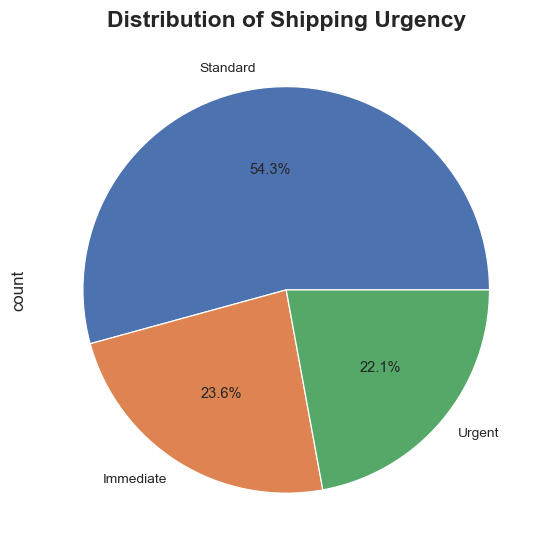

In [136]:
df_deduplicated['Shipping Urgency'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Distribution of Shipping Urgency'
)

plt.show()

Text(0.5, 1.0, 'Profit Distribution by Days to Ship')

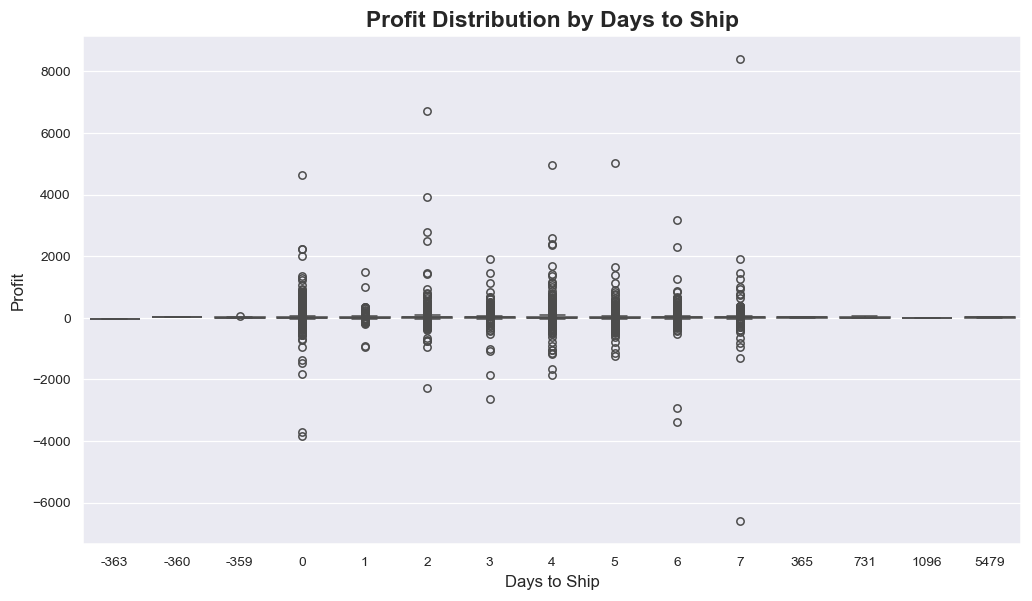

In [137]:
sns.boxplot(
    x='Days to Ship',
    y='Profit',
    data=df_deduplicated
)
plt.title('Profit Distribution by Days to Ship')

## 10. Profit Distribution by Region

In [84]:
region_profit = (
    df_deduplicated
    .groupby('Region')['Total Profit']
    .sum()
    .sort_values(ascending=False)
)
region_profit

Region
West       532880.7637
East       450546.2244
South      227451.8165
Central    219619.2980
Name: Total Profit, dtype: float64

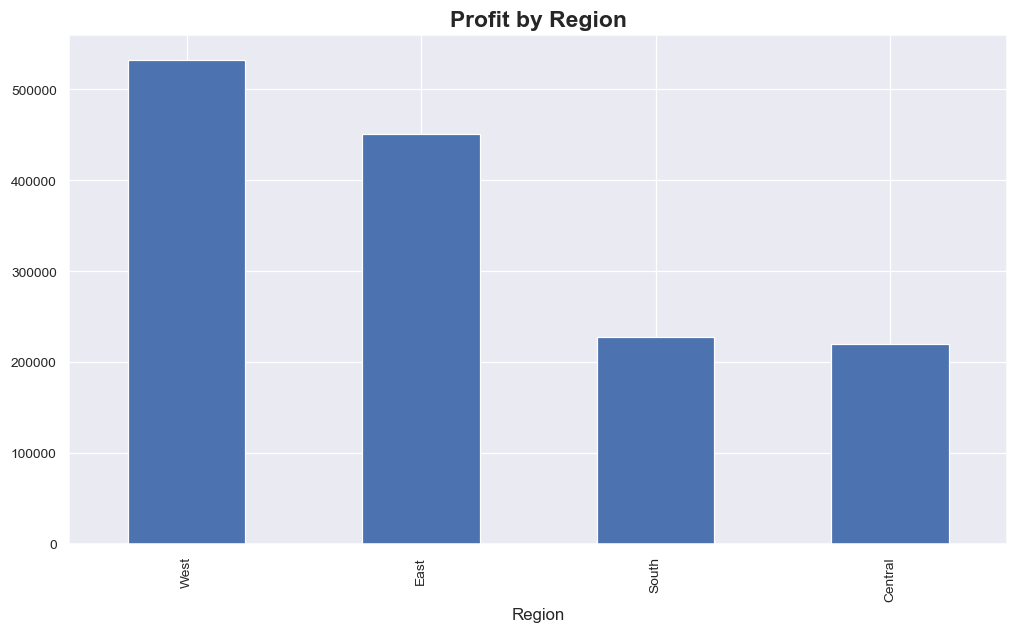

In [128]:
region_profit.plot(
    kind='bar',
    title='Profit by Region'
)
plt.show()

In [86]:
pivot_table = df_deduplicated.pivot_table(
    index='State',
    values='Total Profit',
    aggfunc='sum'
).reset_index()

sorted_pivot_table = pivot_table.sort_values(by='Total Profit',ascending=False)
sorted_pivot_table

,State,Total Profit
31,New York,367020.4694
4,California,361165.6581
46,Washington,165801.3331
21,Michigan,146948.9346
45,Virginia,99084.5224
13,Indiana,89085.4907
10,Georgia,78563.7237
16,Kentucky,58908.6024
22,Minnesota,49259.1076
29,New Jersey,47826.6894


In [87]:
top_state = sorted_pivot_table.iloc[0]
top_state

State              New York
Total Profit    367020.4694
Name: 31, dtype: object

In [102]:
bottom_state = sorted_pivot_table.iloc[-1]
bottom_state

State                 Texas
Total Profit   -135047.1019
Name: 42, dtype: object

Text(0.5, 1.0, 'Sales and Profit Trends Over Time')

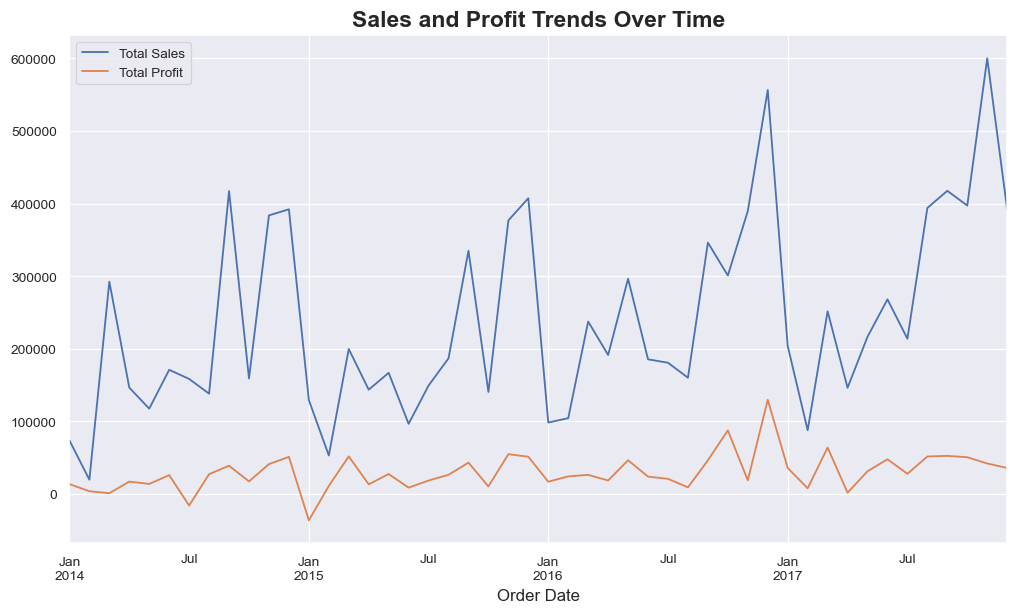

In [129]:
monthly = (df_deduplicated
           .set_index('Order Date')
           .resample('MS')[['Total Sales', 'Total Profit']]
           .sum())
ax = monthly.plot()
ax.set_title('Sales and Profit Trends Over Time')

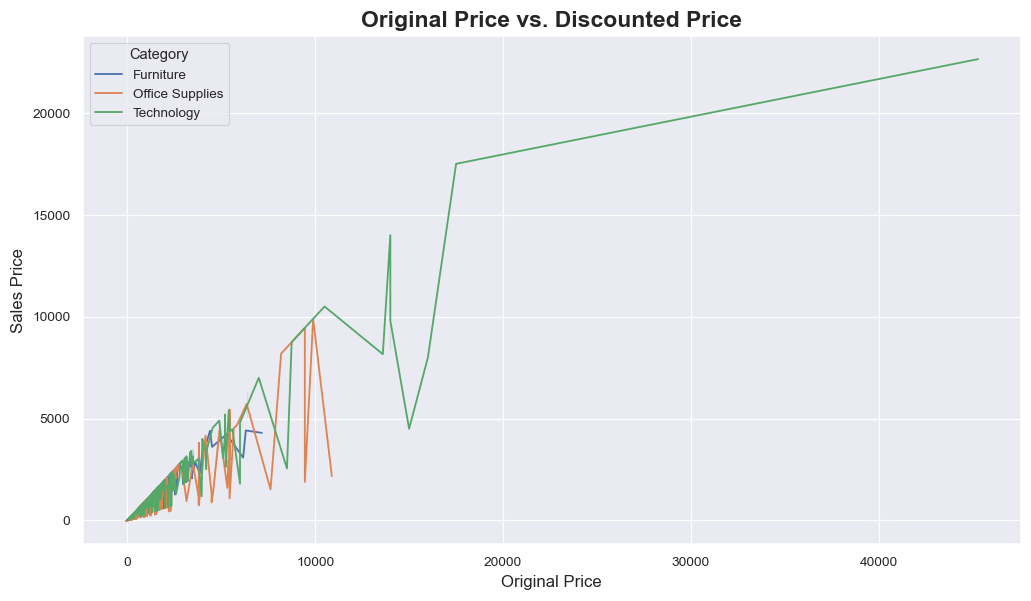

In [134]:
sns.lineplot(
    x='Original Price',
    y='Sales Price',
    hue='Category',
    data=df_deduplicated
)
plt.title('Original Price vs. Discounted Price')
plt.show()

Text(0.5, 1.0, 'Sales and Profit Trends Over Time')

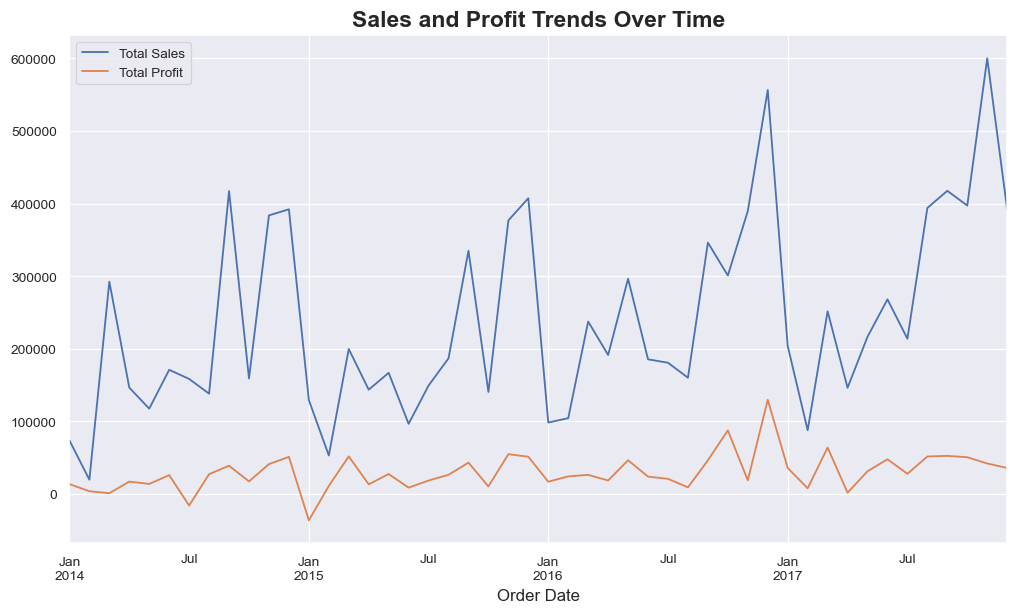

In [133]:
monthly = (df_deduplicated
           .set_index('Order Date')
           .resample('MS')[['Total Sales', 'Total Profit']]
           .sum())
ax = monthly.plot()
ax.set_title('Sales and Profit Trends Over Time')

<Axes: title={'center': 'Order Frequency by Month'}, xlabel='Order Date'>

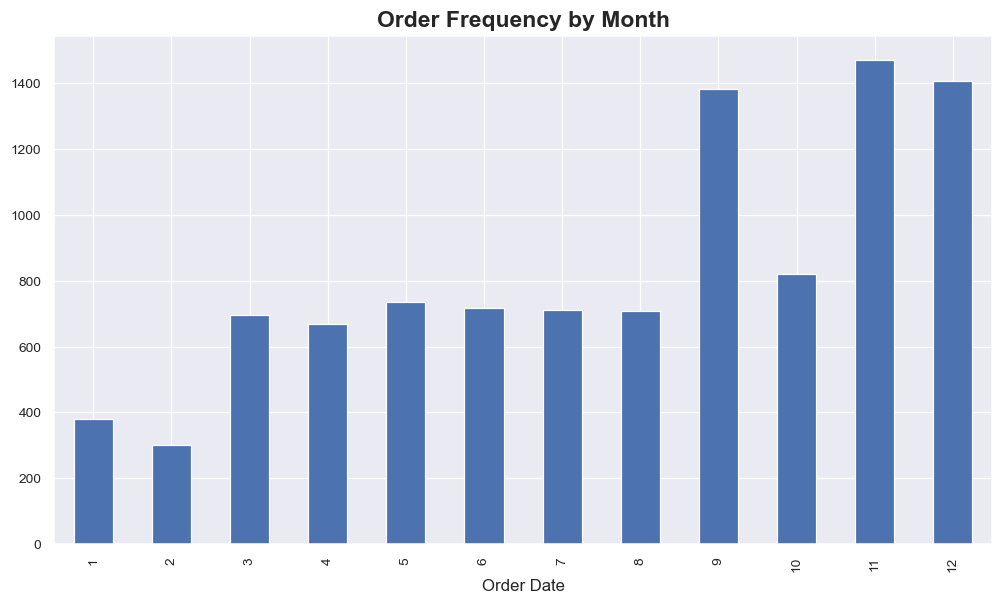

In [131]:
df_deduplicated['Order Date'].dt.month.value_counts().sort_index().plot(kind='bar', 
                                                                        title='Order Frequency by Month')

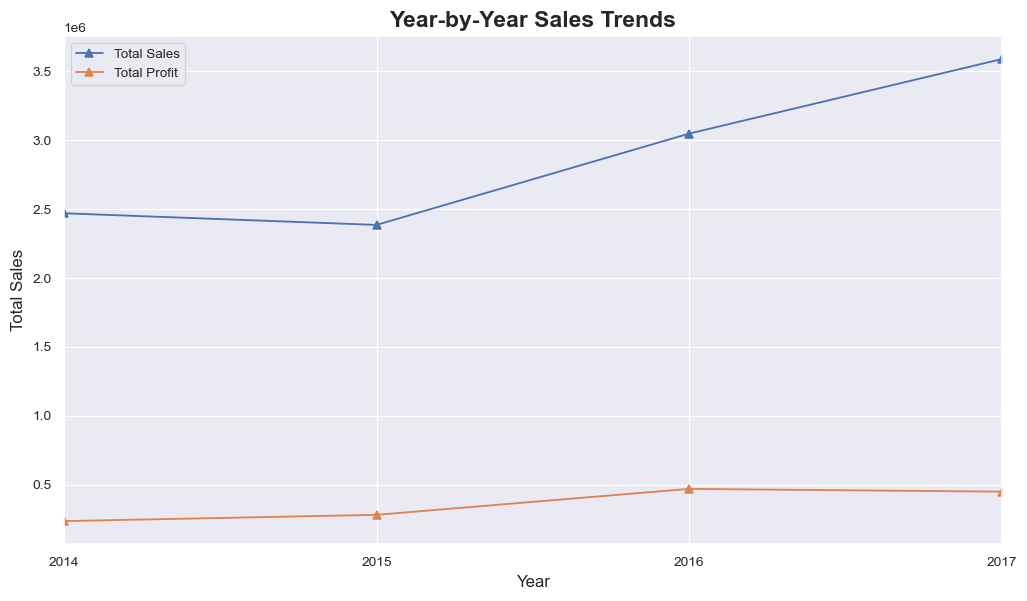

In [135]:
yearly = (df_deduplicated.set_index('Order Date').resample('YS')[['Total Sales' , 'Total Profit']].sum())
ax = yearly.plot(marker = '^')
ax.set_title('Year-by-Year Sales Trends')
ax.set_xlabel('Year')
ax.set_ylabel('Total Sales')
plt.show()

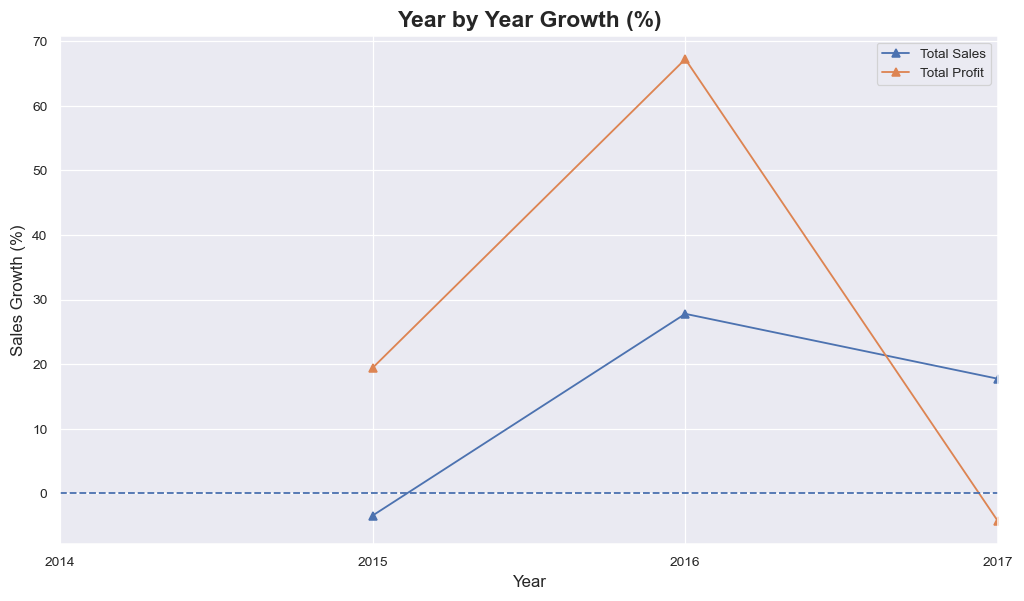

In [132]:
yearly_growth = yearly.pct_change()*100
ax = yearly_growth.plot(marker = '^')
ax.set_title('Year by Year Growth (%)')
ax.set_xlabel('Year')
ax.set_ylabel('Sales Growth (%)')
ax.axhline(0, linestyle = '--')
plt.show()